# Build Your Own Intelligent Drone AI Model Selector

> Imagine that you are developing an intelligent drone.

Your drone needs to perform five tasks:
> 1. Detect people.
> 2. Recognise vehicles.
> 3. Avoid obstacles.
> 4. Identify buildings.
> 5. Monitor environmental conditions.

**Opening discussion:**
Can we install every AI model on the drone?
What happens if the drone has limited memory, processing power, battery, or accelerator capacity?

Today, students will build a small model selector, then scale the same ideas to the supplied 28-model and 90-model assignment datasets.

### Learning outcomes
By the end, students should be able to:
- represent model choices as binary decision variables;
- calculate total utility and resource consumption with NumPy;
- test whether a selection is feasible;
- improve a selection using hill climbing;
- build a genetic algorithm using chromosomes, selection, crossover and mutation;
- compare algorithms using repeated experiments, plots and a Wilcoxon signed-rank test.

## Picture 1 — The intelligent drone and its five AI jobs

Use this picture to introduce the scenario. Ask students to identify which task is safety-critical and whether all five models must always run at the same time.

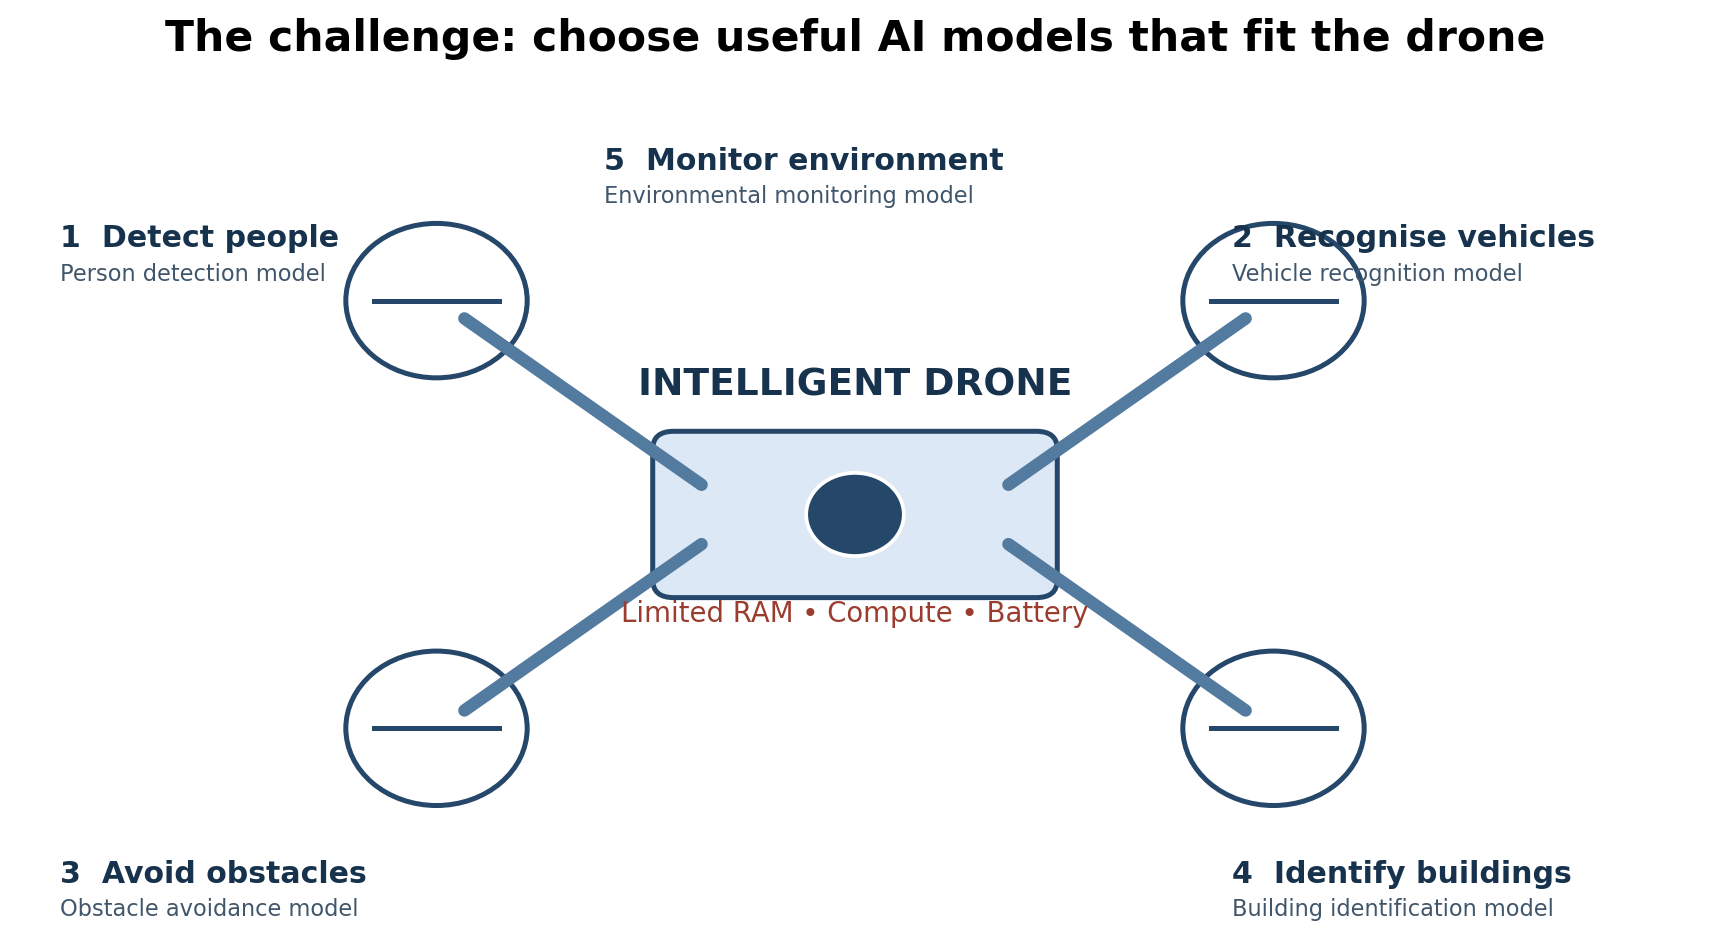

In [1]:
from IPython.display import Image, display
display(Image(filename="drone_lecture_assets/drone_five_tasks.png"))

How the model-selection problem works

Explain the pipeline from left to right. The algorithm does not simply select the models with the largest individual utility. It must evaluate the combined resource use.

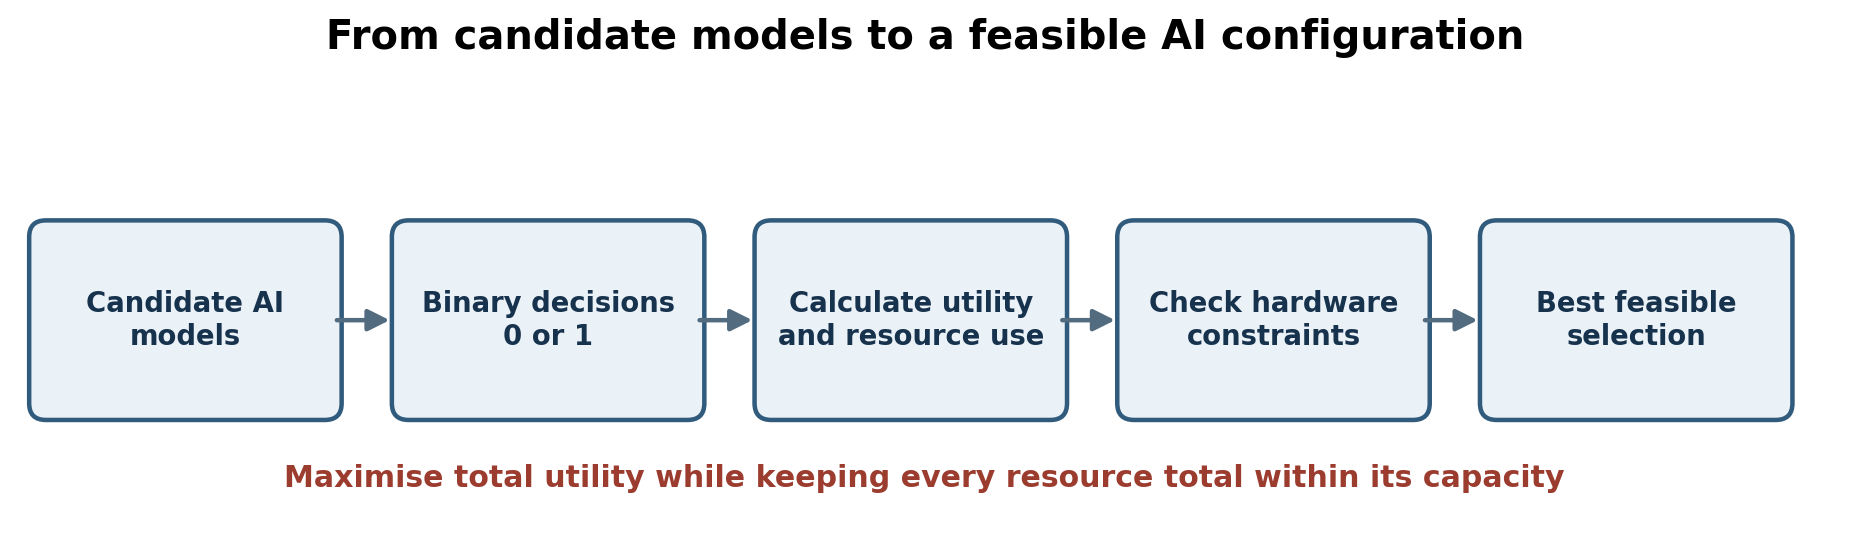

In [2]:
display(Image(filename="drone_lecture_assets/selection_pipeline.png"))

# Stage 1 — understand the problem

## 1.1 The drone's five candidate AI models

Use the following illustrative model information. Utility is a simplified score; RAM and compute are illustrative resource units.

| Index | AI task | Utility | RAM | Compute |
|---:|---|---:|---:|---:|
| 1 | Detect people | 90 | 40 | 30 |
| 2 | Recognise vehicles | 70 | 30 | 20 |
| 3 | Avoid obstacles | 100 | 50 | 40 |
| 4 | Identify buildings | 85 | 35 | 25 |
| 5 | Monitor environment | 60 | 20 | 15 |

Drone hardware limits: **RAM ≤ 100** and **Compute ≤ 70**.

### Questions??
1. Which task has the highest utility?
2. Should we always select the highest-utility models?
3. What is the problem if the total RAM exceeds 100?
4. Can two individually affordable models become unaffordable when selected together?

### Explain the optimisation problem

Each model is either selected (1) or not selected (0). We want the highest total utility without exceeding any hardware limit.

- Decision variable: `x[j]` is 1 if model `j` is selected; otherwise 0.
- Objective: maximise the sum of selected model utilities.
- Constraints: total use of every resource must be within its capacity.

Mathematically:

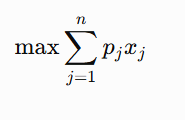\[


subject to:

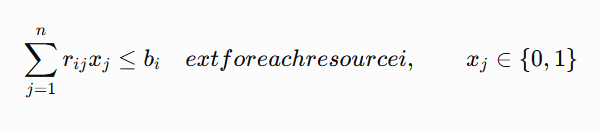

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

model_names = [
    "Detect people",
    "Recognise vehicles",
    "Avoid obstacles",
    "Identify buildings",
    "Monitor environment"
]

utilities = np.array([90, 70, 100, 85, 60])
demands = np.array([
    [40, 30, 50, 35, 20],  # RAM
    [30, 20, 40, 25, 15]   # Compute
])
capacities = np.array([100, 70])

toy_models = pd.DataFrame({
    "AI task": model_names,
    "Utility": utilities,
    "RAM": demands[0],
    "Compute": demands[1]
})
toy_models

,AI task,Utility,RAM,Compute
0,Detect people,90,40,30
1,Recognise vehicles,70,30,20
2,Avoid obstacles,100,50,40
3,Identify buildings,85,35,25
4,Monitor environment,60,20,15


## 1.2 Visualise the five candidate models

Students to l**ook at the table and predict which combination might fit**.
There may be several feasible combinations, but the **best combination** is the one with the greatest utility.

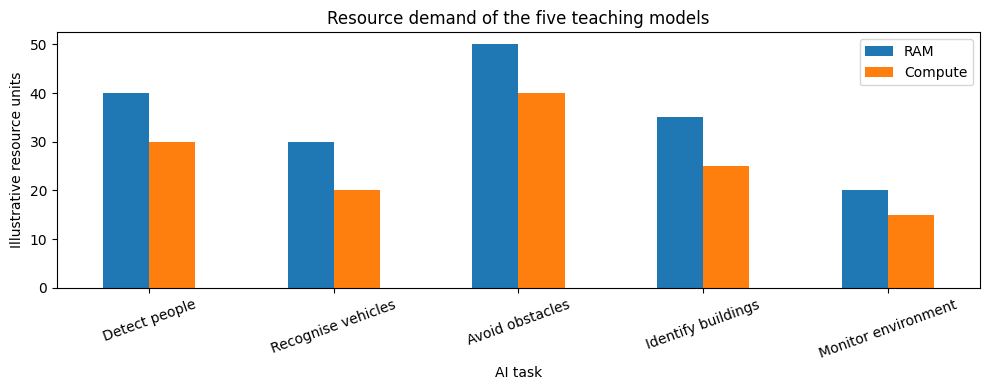

In [4]:
ax = toy_models.set_index("AI task")[["RAM", "Compute"]].plot(
    kind="bar", figsize=(10, 4), rot=20
)
ax.set_title("Resource demand of the five teaching models")
ax.set_ylabel("Illustrative resource units")
plt.tight_layout()
plt.show()

## 1.3 Try a selection by hand

Let the binary vector be:

`[1, 0, 1, 0, 0]`

This means select model **1 (detect people) and model 3 (avoid obstacles). **

Students to calculate the utility, RAM and compute before running the next cell.

In [8]:
x_example = np.array([1, 1, 0, 1, 0])

total_utility = np.dot(utilities, x_example)
resource_use = demands @ x_example
is_feasible = np.all(resource_use <= capacities)

print("Selected models:", [model_names[i] for i in range(len(x_example)) if x_example[i] == 1])
print("Total utility:", total_utility)
print("RAM used:", resource_use[0], "/", capacities[0])
print("Compute used:", resource_use[1], "/", capacities[1])
print("Feasible:", is_feasible)

Selected models: ['Detect people', 'Recognise vehicles', 'Identify buildings']
Total utility: 245
RAM used: 105 / 100
Compute used: 75 / 70
Feasible: False


**Expected result:** Utility = 190, RAM = 90/100, Compute = 70/70, Feasible = True.

### Student activity 1
Change `x_example` to `[1, 1, 0, 1, 0]`. Predict whether it is feasible. Run the cell and explain which resource limit is exceeded.

RAM usage and Compute exceeded design limit.

# Stage 2 — Let students write small Python programs

## 2.1 Understand the binary vector

A binary vector is a list of 0s and 1s. Each position corresponds to one candidate model.

| Binary vector | Meaning |
|---|---|
| `[1,0,0,0,0]` | Select only people detection |
| `[0,1,1,0,0]` | Select vehicle recognition and obstacle avoidance |
| `[1,1,1,1,1]` | Select all five models |

The same representation works for 28 or 90 models. Only the vector length changes.

In [9]:
# Predict the output before running.
x = np.array([1, 1, 0, 1, 0])

print("Number of models selected:", np.sum(x))
print("Binary vector length:", len(x))
print("Utility:", utilities @ x)
print("Resource totals:", demands @ x)

Number of models selected: 3
Binary vector length: 5
Utility: 245
Resource totals: [105  75]


## 2.2 Create reusable calculation functions

- `calculate_utility`: adds the utility of selected models.
- `calculate_resources`: adds the resource demands.
- `check_feasible`: checks every resource against its capacity.
- `show_solution`: displays a readable summary.

In [11]:
def calculate_utility(x, utilities):
    return float(np.dot(utilities, x))

def calculate_resources(x, demands):
    # demands has shape (number_of_resources, number_of_models)
    return demands @ x

def check_feasible(x, demands, capacities):
    usage = calculate_resources(x, demands)
    return bool(np.all(usage <= capacities))

def show_solution(x, names, utilities, demands, capacities):
    usage = calculate_resources(x, demands)
    print("Selected models:")
    for i, bit in enumerate(x):
        if bit == 1:
            print(f"  - {names[i]}")
    print(f"Utility: {calculate_utility(x, utilities):.1f}")
    for i, amount in enumerate(usage):
        print(f"Resource {i+1}: {amount:.1f} / {capacities[i]:.1f}")
    print("Feasible:", check_feasible(x, demands, capacities))

show_solution(np.array([1, 0, 1, 0, 0]), model_names, utilities, demands, capacities)

Selected models:
  - Detect people
  - Avoid obstacles
Utility: 190.0
Resource 1: 90.0 / 100.0
Resource 2: 70.0 / 70.0
Feasible: True


## 2.3 Generate a random selection

A random binary vector is a quick way to create a candidate solution. It may be feasible or infeasible. This is a useful point to introduce the idea that an optimisation algorithm must handle constraints.

In [12]:
import numpy as np

rng = np.random.default_rng(7)

In [13]:
random_solution = rng.integers(
    0, 2, size=len(utilities)
)

print("Random binary vector:", random_solution)

show_solution(
    random_solution,
    model_names,
    utilities,
    demands,
    capacities
)

Random binary vector: [1 1 1 1 1]
Selected models:
  - Detect people
  - Recognise vehicles
  - Avoid obstacles
  - Identify buildings
  - Monitor environment
Utility: 405.0
Resource 1: 175.0 / 100.0
Resource 2: 130.0 / 70.0
Feasible: False


### Student activity 2
1. Generate five random solutions.
2. Print each utility and feasibility.
3. Which random solution has the highest utility?
4. Is the highest-utility random solution necessarily feasible?

**Random candidate solutions**

In [16]:
for run in range(5):

    candidate = rng.integers(
        0, 2, size=len(utilities)
    )

    utility = calculate_utility(
        candidate, utilities
    )

    resources = demands @ candidate

    feasible = check_feasible(
        candidate, demands, capacities
    )

    print(f"\nCandidate {run+1}")
    print("Binary vector:", candidate)
    print("Utility:", utility)
    print("Resource usage:", resources)
    print("Capacities:", capacities)
    print("Feasible:", feasible)


Candidate 1
Binary vector: [1 1 1 0 1]
Utility: 320.0
Resource usage: [140 105]
Capacities: [100  70]
Feasible: False

Candidate 2
Binary vector: [0 0 0 0 1]
Utility: 60.0
Resource usage: [20 15]
Capacities: [100  70]
Feasible: True

Candidate 3
Binary vector: [0 0 0 1 1]
Utility: 145.0
Resource usage: [55 40]
Capacities: [100  70]
Feasible: True

Candidate 4
Binary vector: [1 0 1 0 0]
Utility: 190.0
Resource usage: [90 70]
Capacities: [100  70]
Feasible: True

Candidate 5
Binary vector: [0 1 1 1 0]
Utility: 255.0
Resource usage: [115  85]
Capacities: [100  70]
Feasible: False


# Stage 3 — Introduce intelligent search

## 3.1 What is a search algorithm?

There are \(2^n\) possible binary selections.

For five models there are 32 combinations. For 28 and 90 models, exhaustive checking becomes much more expensive.

An optimisation algorithm searches for good combinations without testing every possible combination.

### Hill climbing analogy
Imagine standing on a hill in fog. You look at nearby positions and move to a better one.

Repeat until none of the nearby moves improves the solution.

In this problem, a **neighbour** is created by flipping one bit:
- 0 becomes 1: add a model;
- 1 becomes 0: remove a model.

In [17]:
def one_bit_neighbours(x):
    neighbours = []
    for i in range(len(x)):
        neighbour = x.copy()
        neighbour[i] = 1 - neighbour[i]
        neighbours.append(neighbour)
    return neighbours

starting = np.array([1, 0, 0, 0, 0])
print("Starting:", starting)
print("One-bit neighbours:")
for neighbour in one_bit_neighbours(starting):
    print(neighbour)

Starting: [1 0 0 0 0]
One-bit neighbours:
[0 0 0 0 0]
[1 1 0 0 0]
[1 0 1 0 0]
[1 0 0 1 0]
[1 0 0 0 1]


**Note**
In hill climbing, we start with one candidate solution and generate its neighbours.
We evaluate those neighbours and move towards a better solution.

The starting solution can be manually defined for demonstration or randomly generated in the actual optimisation algorithm.

## 3.2 Constraint handling: repair an infeasible solution

A simple repair strategy repeatedly removes a selected model until the solution is feasible. Here we remove the selected model with the lowest utility per unit of normalised resource use.

This is a teaching heuristic, not a guarantee of a globally optimal repair. In the assignment, explain and justify your chosen constraint-handling method.

In [18]:
def repair_solution(x, utilities, demands, capacities):
    x = x.copy().astype(int)
    while np.any(demands @ x > capacities):
        selected = np.where(x == 1)[0]
        if len(selected) == 0:
            break

        # Normalise each resource by its capacity to make resource scales comparable.
        normalised_cost = (demands[:, selected] / capacities[:, None]).sum(axis=0)
        scores = utilities[selected] / np.maximum(normalised_cost, 1e-12)
        remove_index = selected[np.argmin(scores)]
        x[remove_index] = 0
    return x

bad_solution = np.ones(len(utilities), dtype=int)
print("Before repair:", bad_solution, "feasible:", check_feasible(bad_solution, demands, capacities))
fixed_solution = repair_solution(bad_solution, utilities, demands, capacities)
print("After repair: ", fixed_solution, "feasible:", check_feasible(fixed_solution, demands, capacities))
show_solution(fixed_solution, model_names, utilities, demands, capacities)

Before repair: [1 1 1 1 1] feasible: False
After repair:  [0 1 0 1 1] feasible: True
Selected models:
  - Recognise vehicles
  - Identify buildings
  - Monitor environment
Utility: 215.0
Resource 1: 85.0 / 100.0
Resource 2: 60.0 / 70.0
Feasible: True


## 3.3 Build a hill climber

Algorithm:
1. Create a random binary solution.
2. Repair it so it satisfies the resource limits.
3. Generate one-bit neighbours.
4. Repair each neighbour.
5. Evaluate their utility.
6. Move to the best neighbour if it improves the current solution.
7. Stop when no neighbour improves it or the evaluation budget is used.

**Note:** This is a simple baseline. Hill climbing can get stuck in a local optimum, so we will later compare it with a population-based method.

Best utility: 220.0
Evaluations: 6
Selected models:
  - Detect people
  - Recognise vehicles
  - Monitor environment
Utility: 220.0
Resource 1: 90.0 / 100.0
Resource 2: 65.0 / 70.0
Feasible: True


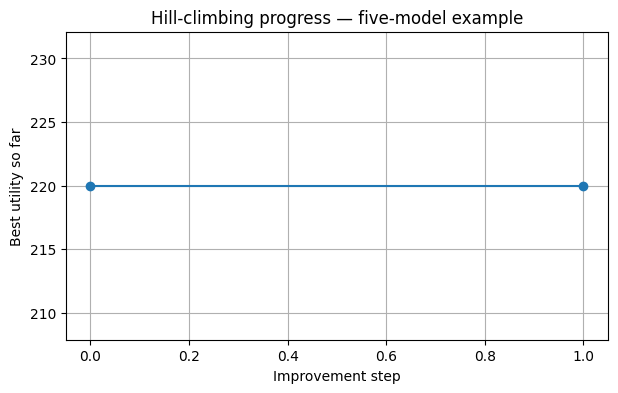

In [19]:
def hill_climber(utilities, demands, capacities, max_evaluations=500, seed=1):
    rng = np.random.default_rng(seed)
    n = len(utilities)
    current = rng.integers(0, 2, size=n)
    current = repair_solution(current, utilities, demands, capacities)

    evaluations = 1
    best_value = calculate_utility(current, utilities)
    history = [best_value]

    while evaluations < max_evaluations:
        neighbours = one_bit_neighbours(current)
        candidates = []

        for neighbour in neighbours:
            if evaluations >= max_evaluations:
                break
            neighbour = repair_solution(neighbour, utilities, demands, capacities)
            value = calculate_utility(neighbour, utilities)
            evaluations += 1
            candidates.append((value, neighbour))

        if not candidates:
            break

        candidate_value, candidate = max(candidates, key=lambda item: item[0])
        if candidate_value > best_value:
            current = candidate
            best_value = candidate_value
        else:
            # No improving one-bit neighbour: stop at this local optimum.
            history.append(best_value)
            break

        history.append(best_value)

    return current, best_value, history, evaluations

hc_solution, hc_value, hc_history, hc_evals = hill_climber(
    utilities, demands, capacities, max_evaluations=100, seed=10
)
print("Best utility:", hc_value)
print("Evaluations:", hc_evals)
show_solution(hc_solution, model_names, utilities, demands, capacities)

plt.figure(figsize=(7, 4))
plt.plot(hc_history, marker="o")
plt.xlabel("Improvement step")
plt.ylabel("Best utility so far")
plt.title("Hill-climbing progress — five-model example")
plt.grid(True)
plt.show()

## 3.4 Mutation and random restarts

Mutation means changing one or more bits at random. A random restart starts from a new solution and can help escape a local optimum.

### Student activity 3
1. Change the hill-climber seed to 1, 2, 3, 4 and 5.
2. Record the best utility from each run.
3. Are the results identical?
4. Why might a local search algorithm find different solutions?

The results are not identical across different seed values

**Change the hill-climber seed to 1, 2, 3, 4 and 5.**

In [34]:
import pandas as pd

results = []

# Execute hill climbing five times
for seed in range(1, 6):

    solution, best_value, history, evaluations = hill_climber(
        utilities,
        demands,
        capacities,
        max_evaluations=100,
        seed=seed
    )

    # Store the results
    results.append({
        "Run": seed,
        "Seed": seed,
        "Best Utility": best_value,
        "Selected Models": sum(solution),
        "Feasible": check_feasible(
            solution, demands, capacities
        ),
        "Evaluations": evaluations
    })

# Convert results into a DataFrame
results_df = pd.DataFrame(results)

# Display results
display(results_df)

,Run,Seed,Best Utility,Selected Models,Feasible,Evaluations
0,1,1,215.0,3,True,11
1,2,2,190.0,2,True,11
2,3,3,190.0,2,True,11
3,4,4,215.0,3,True,6
4,5,5,215.0,3,True,11


**Record the best utility from each run.**

In [35]:
print("Best utility:", results_df["Best Utility"].max())

print("Worst utility:", results_df["Best Utility"].min())

print("Average utility:", results_df["Best Utility"].mean())

print("Standard deviation:", results_df["Best Utility"].std())

Best utility: 215.0
Worst utility: 190.0
Average utility: 205.0
Standard deviation: 13.693063937629153


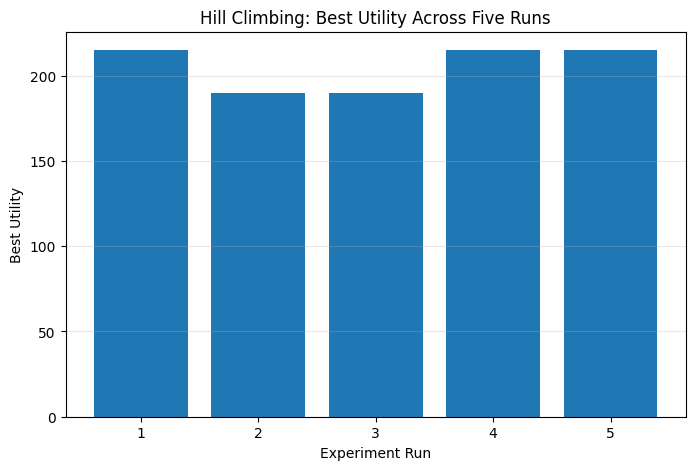

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    results_df["Run"],
    results_df["Best Utility"]
)

plt.xlabel("Experiment Run")
plt.ylabel("Best Utility")
plt.title("Hill Climbing: Best Utility Across Five Runs")

plt.xticks(range(1, 6))
plt.grid(axis="y", alpha=0.3)

plt.show()

**Question 3: Are the results identical?**

Check the Best Utility column.
- If the values differ, the algorithm found different-quality solutions.
- If all values are identical, the algorithm found the same best utility in these five trials.

**Question 4: Why might a local search algorithm find different solutions?**

Because:
- Each seed can generate a different initial solution.
- Each initial solution can have different neighbours.
- Hill climbing may become trapped in different local optima.
- Random restarts or random neighbour ordering can affect the search path.

## Genetic algorithm cycle

Walk around this diagram with the class. Ask students what information is passed from one stage to the next, and why the repair stage is needed after crossover and mutation.

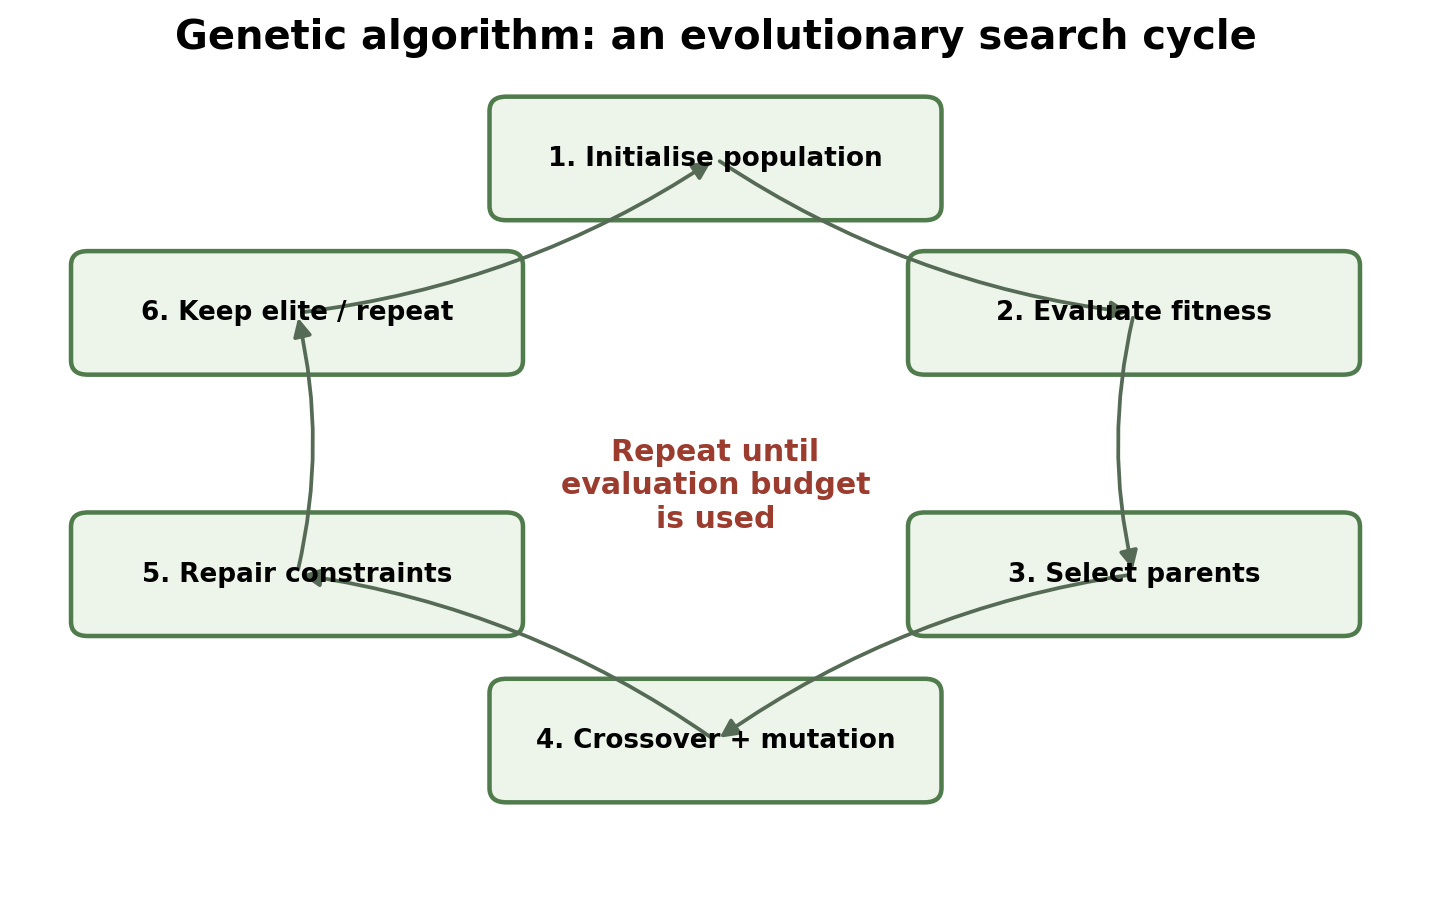

In [37]:
display(Image(filename="drone_lecture_assets/genetic_algorithm_cycle.png"))

# Stage 4 — Introduce evolutionary optimisation

## 4.1 Genetic algorithm: think like evolution

A genetic algorithm maintains a **population** of candidate solutions.

| Biology idea | Optimisation meaning |
|---|---|
| Individual | Candidate solution |
| Chromosome | Binary vector |
| Gene | One model-selection bit |
| Fitness | Utility of a feasible solution |
| Parent selection | Choose candidates to reproduce |
| Crossover | Combine parts of two parents |
| Mutation | Randomly flip bits |
| Elitism | Preserve the best candidate |

### The cycle
Initial population → Evaluate → Select parents → Crossover → Mutate → Repair → New population → Repeat.

In [38]:
def random_feasible_solution(utilities, demands, capacities, rng):
    x = rng.integers(0, 2, size=len(utilities))
    return repair_solution(x, utilities, demands, capacities)

def tournament_selection(population, fitness, rng, tournament_size=3):
    chosen = rng.choice(len(population), size=tournament_size, replace=False)
    winner = chosen[np.argmax(fitness[chosen])]
    return population[winner].copy()

def uniform_crossover(parent1, parent2, rng):
    mask = rng.integers(0, 2, size=len(parent1)).astype(bool)
    child = np.where(mask, parent1, parent2)
    return child

def bit_flip_mutation(child, mutation_rate, rng):
    mask = rng.random(len(child)) < mutation_rate
    mutated = child.copy()
    mutated[mask] = 1 - mutated[mask]
    return mutated

## 4.2 Assemble the genetic algorithm

We will implement the algorithm ourselves using NumPy. No pre-packaged genetic-algorithm framework is used.

To make comparisons fair later, the algorithm accepts a fixed number of fitness evaluations. The returned history records the best-so-far fitness after each generation.

Best utility: 235.0
Fitness evaluations: 300
Selected models:
  - Detect people
  - Identify buildings
  - Monitor environment
Utility: 235.0
Resource 1: 95.0 / 100.0
Resource 2: 70.0 / 70.0
Feasible: True


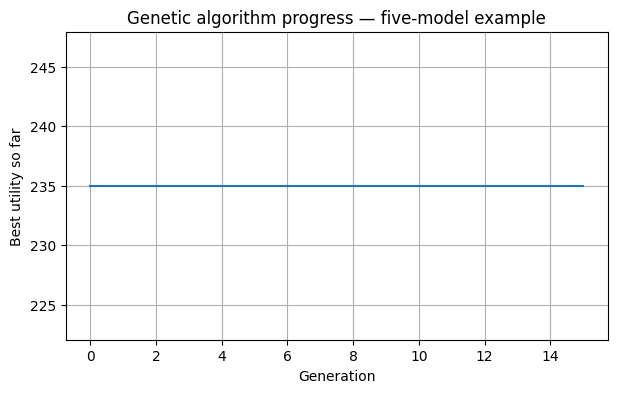

In [39]:
def genetic_algorithm(
    utilities, demands, capacities,
    population_size=30,
    max_evaluations=900,
    mutation_rate=None,
    crossover="uniform",
    seed=1
):
    rng = np.random.default_rng(seed)
    n = len(utilities)
    if mutation_rate is None:
        mutation_rate = 1 / n

    population = np.array([
        random_feasible_solution(utilities, demands, capacities, rng)
        for _ in range(population_size)
    ], dtype=int)

    fitness = np.array([calculate_utility(x, utilities) for x in population])
    evaluations = population_size
    best_idx = int(np.argmax(fitness))
    best_solution = population[best_idx].copy()
    best_fitness = float(fitness[best_idx])
    history = [best_fitness]

    while evaluations < max_evaluations:
        new_population = [best_solution.copy()]  # elitism

        while len(new_population) < population_size and evaluations < max_evaluations:
            p1 = tournament_selection(population, fitness, rng)
            p2 = tournament_selection(population, fitness, rng)

            if crossover == "uniform":
                child = uniform_crossover(p1, p2, rng)
            elif crossover == "one_point":
                point = rng.integers(1, n)
                child = np.concatenate([p1[:point], p2[point:]])
            else:
                raise ValueError("crossover must be 'uniform' or 'one_point'")

            child = bit_flip_mutation(child, mutation_rate, rng)
            child = repair_solution(child, utilities, demands, capacities)

            child_fitness = calculate_utility(child, utilities)
            evaluations += 1
            new_population.append(child)

            if child_fitness > best_fitness:
                best_fitness = float(child_fitness)
                best_solution = child.copy()

        # Evaluate any population members already known; elitism and generated
        # children have fitness values, so only new children need evaluations.
        population = np.array(new_population, dtype=int)
        fitness = np.array([calculate_utility(x, utilities) for x in population])
        history.append(best_fitness)

    return best_solution, best_fitness, history, evaluations

ga_solution, ga_value, ga_history, ga_evals = genetic_algorithm(
    utilities, demands, capacities,
    population_size=20, max_evaluations=300,
    seed=21
)
print("Best utility:", ga_value)
print("Fitness evaluations:", ga_evals)
show_solution(ga_solution, model_names, utilities, demands, capacities)

plt.figure(figsize=(7, 4))
plt.plot(ga_history)
plt.xlabel("Generation")
plt.ylabel("Best utility so far")
plt.title("Genetic algorithm progress — five-model example")
plt.grid(True)
plt.show()

**Fitness represents how good a solution is.**
AI model	Utility
Detect people	90
Identify buildings	85
Monitor environment	60
Total	235
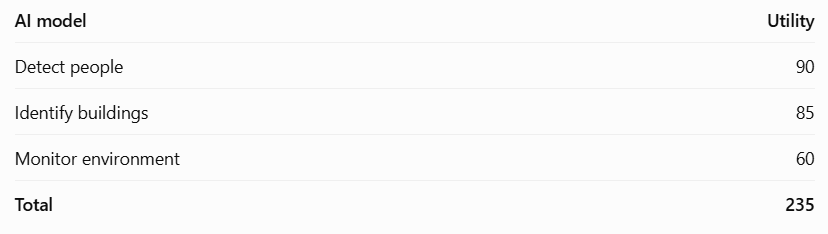
Therefore:
\[
Fitness = 90+85+60 = 235
\]

What is Resource 1?
Resource 1 represents the first hardware constraint in our teaching dataset: RAM.
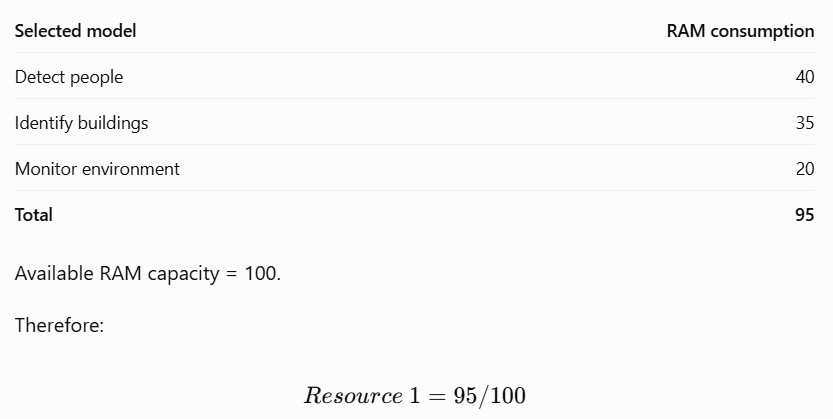
95% RAM used
The drone uses 95 units out of 100 available units.
3. What is Resource 2?
Resource 2 represents the second hardware constraint: Compute.
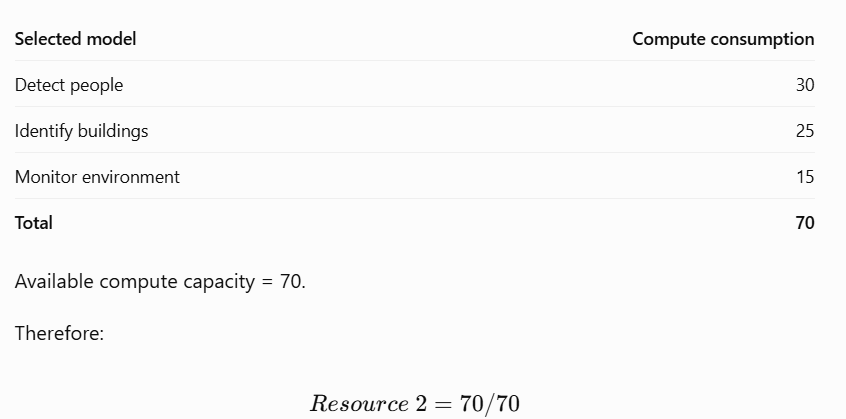


### Student activity 4 — change the algorithm
Try the following changes one at a time:
1. `population_size=10` and then `population_size=40`.
2. `mutation_rate=0.05` and then `mutation_rate=0.30`.
3. `crossover="uniform"` and `crossover="one_point"`.

Before each run, predict what may happen. Then compare the best utility and explain why changing a parameter can affect search behaviour.

**Debugging questions**
- What happens if repair is removed?
- Why do we preserve an elite solution?
- What could happen if mutation is too low?
- What could happen if mutation is too high?

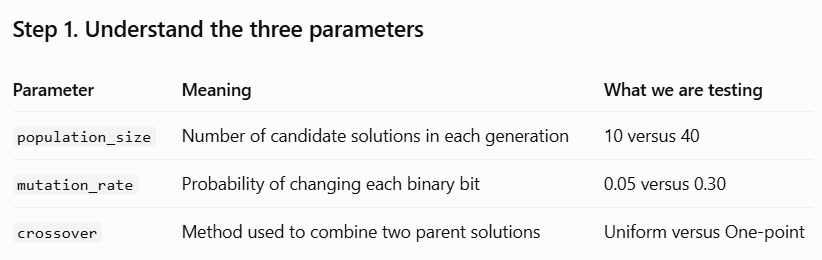

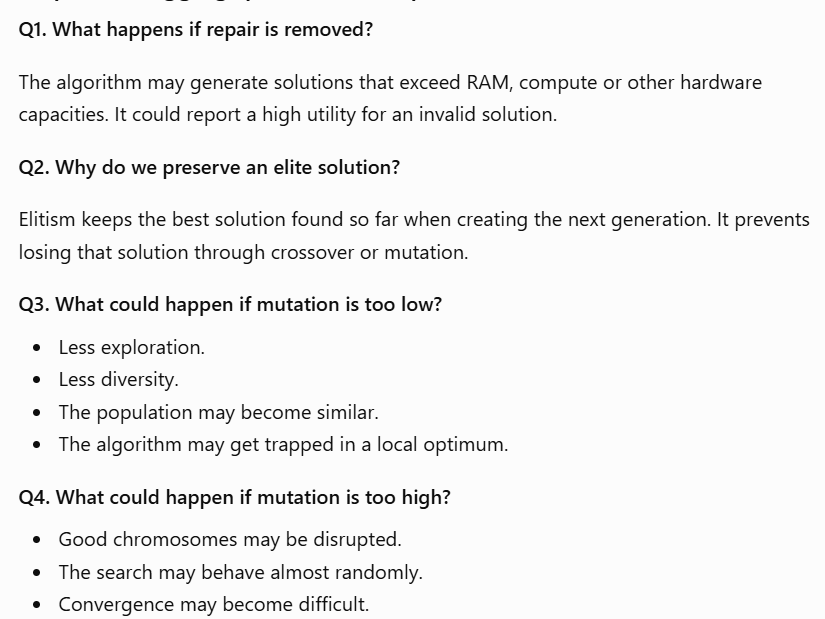

# Stage 5 — Conduct research experiments

A single run is not enough to judge a stochastic algorithm. Different random seeds can produce different outcomes.

## 5.1 Design a fair comparison

For a research comparison:
- compare two clearly defined variants;
- use the same dataset and resource limits;
- use the same population size and mutation rate;
- use the same fitness-evaluation budget;
- use at least 30 independent runs;
- use a predeclared significance level, commonly 0.05.

In this experiment we compare **uniform crossover** against **one-point crossover**. The hypothesis is that uniform crossover may be more flexible because the order of model indices has no inherent meaning. This is a hypothesis to test, not a guaranteed result.

In [84]:
def run_comparison(
    utilities, demands, capacities,
    seeds=range(30),
    population_size=30,
    evaluation_budget=900,
    mutation_rate=None
):
    rows = []
    histories = {"uniform": [], "one_point": []}

    for seed in seeds:
        for method in ["uniform", "one_point"]:
            solution, value, history, evaluations = genetic_algorithm(
                utilities, demands, capacities,
                population_size=population_size,
                max_evaluations=evaluation_budget,
                mutation_rate=mutation_rate,
                crossover=method,
                seed=int(seed)
            )
            rows.append({
                "seed": int(seed),
                "variant": method,
                "best_utility": value,
                "evaluations": evaluations,
                "feasible": check_feasible(solution, demands, capacities),
                "selected_models": int(solution.sum())
            })
            histories[method].append(history)

    return pd.DataFrame(rows), histories

# Demonstration on the five-model teaching example (30 paired runs).
demo_results, demo_histories = run_comparison(
    utilities, demands, capacities,
    seeds=range(30),
    population_size=20,
    evaluation_budget=200
)
demo_results.head()

,seed,variant,best_utility,evaluations,feasible,selected_models
0,0,uniform,235.0,200,True,3
1,0,one_point,235.0,200,True,3
2,1,uniform,235.0,200,True,3
3,1,one_point,235.0,200,True,3
4,2,uniform,235.0,200,True,3


## 5.2 Summarise results and plot a boxplot

,count,mean,std,median,min,max
variant,,,,,,
one_point,30,235.0,0.0,235.0,235.0,235.0
uniform,30,235.0,0.0,235.0,235.0,235.0


<Figure size 700x400 with 0 Axes>

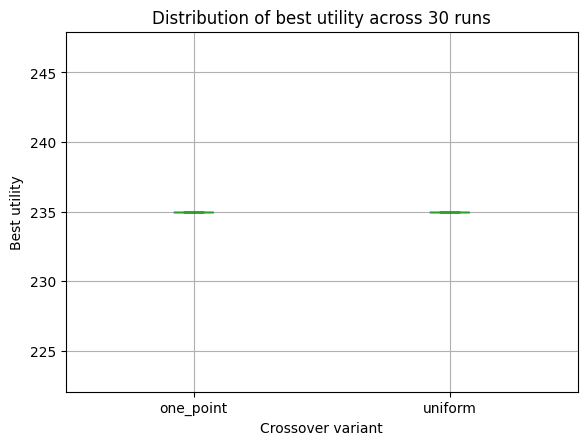

In [85]:
summary = demo_results.groupby("variant")["best_utility"].agg(
    ["count", "mean", "std", "median", "min", "max"]
)
display(summary)

plt.figure(figsize=(7, 4))
demo_results.boxplot(column="best_utility", by="variant")
plt.suptitle("")
plt.title("Distribution of best utility across 30 runs")
plt.ylabel("Best utility")
plt.xlabel("Crossover variant")
plt.grid(True, axis="y")
plt.show()

## 5.3 Compare convergence

The curves below show the average best-so-far utility by generation across the repeated runs. Curves are useful for visual comparison, but statistical testing should use the per-run outcomes.

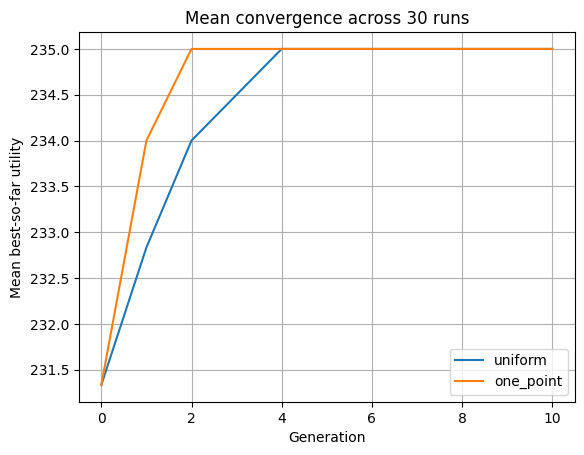

In [ ]:
for method, runs in demo_histories.items():
    max_len = max(len(h) for h in runs)
    padded = np.array([
        np.pad(h, (0, max_len-len(h)), mode="edge")
        for h in runs
    ])
    plt.plot(padded.mean(axis=0), label=method)

plt.xlabel("Generation")
plt.ylabel("Mean best-so-far utility")
plt.title("Mean convergence across 30 runs")
plt.legend()
plt.grid(True)
plt.show()

## 5.4 Wilcoxon signed-rank test

Because both variants use the same run seeds, compare paired results by seed. The Wilcoxon signed-rank test is a non-parametric test for paired samples.

- Null hypothesis (H0): the paired outcome differences are centred around zero.
- Alternative hypothesis (H1): the paired outcomes differ.
- If p < 0.05, reject H0 at the 5% significance level.
- If p ≥ 0.05, there is insufficient evidence to reject H0. This does **not** prove the algorithms are identical.

If all paired differences are zero, the test is not informative; the code handles that case.

In [86]:
from scipy.stats import wilcoxon

paired = demo_results.pivot(index="seed", columns="variant", values="best_utility")
differences = paired["uniform"] - paired["one_point"]

if np.allclose(differences, 0):
    print("All paired differences are zero; Wilcoxon test is not informative.")
else:
    statistic, p_value = wilcoxon(
        paired["uniform"], paired["one_point"],
        alternative="two-sided",
        zero_method="wilcox"
    )
    print("Wilcoxon statistic:", statistic)
    print("p-value:", p_value)
    print("Median paired difference (uniform - one_point):", differences.median())
    if p_value < 0.05:
        print("Decision: statistically significant difference at alpha = 0.05.")
    else:
        print("Decision: no statistically significant difference at alpha = 0.05.")

All paired differences are zero; Wilcoxon test is not informative.


# Stage 6 — Complete the actual assignment

The supplied assignment instances are:
- `multi_resource_n28_m2.txt`: 28 candidate models and 2 resource constraints.
- `multi_resource_n90_m5.txt`: 90 candidate models and 5 resource constraints.
- `workload_data_loader.py`: supplied loader function `load_workload_instance(file_path)`.

The five-model drone data above is only a teaching example. In this final stage, use the supplied files and their exact values.

## 6.1 Put the three supplied files in the same folder as this notebook

Required files:
- `multi_resource_n28_m2.txt`
- `multi_resource_n90_m5.txt`
- `workload_data_loader.py`

If you use Google Colab, upload the three files into the session. If you use Jupyter locally, place them beside this notebook.

In [87]:
from pathlib import Path
import importlib.util

DATA_DIR = Path(".")
helper_path = DATA_DIR / "workload_data_loader.py"

if not helper_path.exists():
    raise FileNotFoundError(
        "Place workload_data_loader.py in the same folder as this notebook."
    )

spec = importlib.util.spec_from_file_location("workload_data_loader", helper_path)
loader_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(loader_module)
load_workload_instance = loader_module.load_workload_instance

def load_assignment_instance(filename):
    path = DATA_DIR / filename
    if not path.exists():
        raise FileNotFoundError(f"Cannot find {filename}. Put it beside this notebook.")
    n, m, utilities_data, demands_data, capacities_data = load_workload_instance(str(path))
    u = np.asarray(utilities_data, dtype=float)
    d = np.asarray(demands_data, dtype=float)
    b = np.asarray(capacities_data, dtype=float)
    assert len(u) == n, "Utility vector length does not match n."
    assert d.shape == (m, n), f"Expected demands shape {(m, n)}, got {d.shape}."
    assert len(b) == m, "Capacity vector length does not match m."
    return n, m, u, d, b

n28, m28, u28, d28, b28 = load_assignment_instance("multi_resource_n28_m2.txt")
n90, m90, u90, d90, b90 = load_assignment_instance("multi_resource_n90_m5.txt")

print("Instance 1: n =", n28, "| resources =", m28, "| capacities =", b28)
print("Instance 2: n =", n90, "| resources =", m90, "| capacities =", b90)

Instance 1: n = 28 | resources = 2 | capacities = [500. 500.]
Instance 2: n = 90 | resources = 5 | capacities = [2100. 1100. 3300. 3700. 3600.]


## 6.2 Part 1 — Baseline hill climber on the 28-model instance

Suggested workflow:
1. Load the 28-model instance.
2. Run the baseline hill climber many times with different seeds.
3. Record best utility, evaluations, runtime and feasibility.
4. Report mean, standard deviation, best and worst utility.
5. Plot convergence and discuss variability.

The function below uses a strict evaluation budget and stores the best-so-far value at each evaluated neighbour.

In [88]:
def hill_climber_strict(utilities, demands, capacities, max_evaluations=3000, seed=1):
    rng = np.random.default_rng(seed)
    n = len(utilities)
    current = repair_solution(
        rng.integers(0, 2, size=n), utilities, demands, capacities
    )
    evaluations = 1
    best_value = calculate_utility(current, utilities)
    history = [best_value]

    while evaluations < max_evaluations:
        best_neighbour = None
        best_neighbour_value = best_value

        order = rng.permutation(n)
        for i in order:
            if evaluations >= max_evaluations:
                break
            neighbour = current.copy()
            neighbour[i] = 1 - neighbour[i]
            neighbour = repair_solution(neighbour, utilities, demands, capacities)
            value = calculate_utility(neighbour, utilities)
            evaluations += 1
            if value > best_neighbour_value:
                best_neighbour = neighbour
                best_neighbour_value = value
            history.append(max(best_value, best_neighbour_value))

        if best_neighbour is None:
            # Random perturbation to encourage escape from a local optimum.
            if evaluations >= max_evaluations:
                break
            current = rng.integers(0, 2, size=n)
            current = repair_solution(current, utilities, demands, capacities)
            best_value = calculate_utility(current, utilities)
            evaluations += 1
            history.append(best_value)
        else:
            current = best_neighbour
            best_value = best_neighbour_value

    return current, best_value, history, evaluations

import time

part1_rows = []
part1_histories = []
for seed in range(30):
    start = time.perf_counter()
    sol, value, hist, evals = hill_climber_strict(
        u28, d28, b28, max_evaluations=3000, seed=seed
    )
    elapsed = time.perf_counter() - start
    part1_rows.append({
        "seed": seed, "best_utility": value,
        "evaluations": evals, "runtime_seconds": elapsed,
        "feasible": check_feasible(sol, d28, b28),
        "selected_models": int(sol.sum())
    })
    part1_histories.append(hist)

part1_results = pd.DataFrame(part1_rows)
display(part1_results.head())
display(part1_results[["best_utility", "runtime_seconds", "selected_models"]].describe())
print("Feasibility rate:", part1_results["feasible"].mean() * 100, "%")

,seed,best_utility,evaluations,runtime_seconds,feasible,selected_models
0,0,93712.0,3000,0.154634,True,15
1,1,129173.0,3000,0.109105,True,10
2,2,120735.0,3000,0.127763,True,12
3,3,82222.0,3000,0.115747,True,13
4,4,114469.0,3000,0.109574,True,10


,best_utility,runtime_seconds,selected_models
count,30.000000,30.000000,30.000000
mean,118127.466667,0.111531,10.466667
std,12648.826779,0.010907,1.995397
min,82222.000000,0.101855,7.000000
25%,113946.250000,0.105508,10.000000
50%,121001.500000,0.107764,10.000000
75%,128994.250000,0.111596,11.000000
max,129778.000000,0.154634,16.000000


Feasibility rate: 100.0 %


## 6.3 Part 2 — Advanced population-based method on the 90-model instance

Use the genetic algorithm from Stage 4 as a baseline advanced method, then improve or justify its design:
- selection: tournament selection;
- crossover: uniform or one-point;
- mutation: bit-flip mutation;
- constraint handling: repair;
- elitism: preserve the best solution.

You can experiment with population size, mutation rate, crossover, tournament size, repair strategy and restart policy. Explain why each design choice is appropriate for a binary constrained problem.

In [ ]:
part2_solution, part2_value, part2_history, part2_evals = genetic_algorithm(
    u90, d90, b90,
    population_size=60,
    max_evaluations=4800,
    mutation_rate=1/len(u90),
    crossover="uniform",
    seed=42
)
print("Part 2 best utility:", part2_value)
print("Evaluations:", part2_evals)
print("Feasible:", check_feasible(part2_solution, d90, b90))
print("Selected models:", int(part2_solution.sum()))
print("Resource use:", d90 @ part2_solution)
print("Capacities:", b90)

Part 2 best utility: 11130.0
Evaluations: 4800
Feasible: True
Selected models: 48
Resource use: [1715. 1100. 2068. 1973. 2295.]
Capacities: [2100. 1100. 3300. 3700. 3600.]


## 6.4 Part 3 — Compare two variants on the 90-model instance

Use at least 30 independent paired seeds and the same evaluation budget for both variants. The following experiment compares uniform and one-point crossover with the same population size, mutation rate, selection and repair.

In [89]:
part3_results, part3_histories = run_comparison(
    u90, d90, b90,
    seeds=range(30),
    population_size=60,
    evaluation_budget=4800,
    mutation_rate=1/len(u90)
)

display(part3_results.head())
display(part3_results.groupby("variant").agg(
    mean_utility=("best_utility", "mean"),
    std_utility=("best_utility", "std"),
    median_utility=("best_utility", "median"),
    best_utility=("best_utility", "max"),
    worst_utility=("best_utility", "min"),
    feasibility_rate=("feasible", "mean"),
    mean_selected=("selected_models", "mean")
))

,seed,variant,best_utility,evaluations,feasible,selected_models
0,0,uniform,11073.0,4800,True,47
1,0,one_point,11071.0,4800,True,47
2,1,uniform,11047.0,4800,True,46
3,1,one_point,11068.0,4800,True,47
4,2,uniform,11079.0,4800,True,46


,mean_utility,std_utility,median_utility,best_utility,worst_utility,feasibility_rate,mean_selected
variant,,,,,,,
one_point,11074.4,48.625664,11073.5,11166.0,10949.0,1.0,46.966667
uniform,11095.8,46.482032,11105.0,11155.0,10976.0,1.0,47.033333


<Figure size 700x400 with 0 Axes>

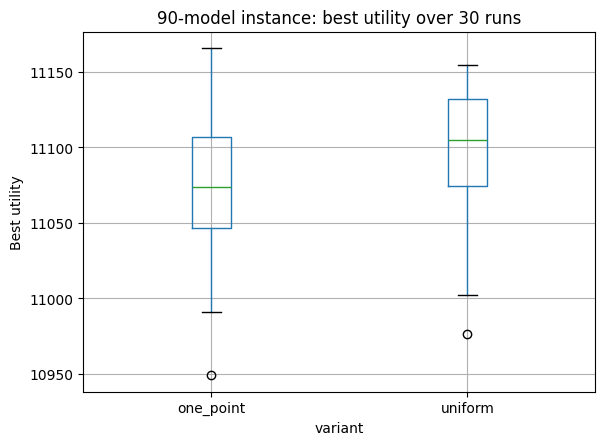

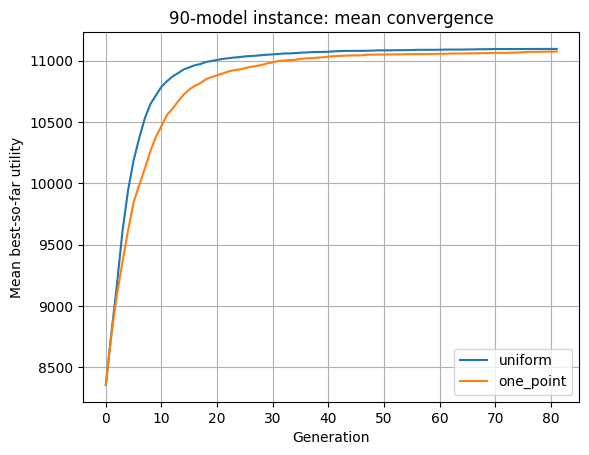

In [90]:
plt.figure(figsize=(7, 4))
part3_results.boxplot(column="best_utility", by="variant")
plt.suptitle("")
plt.title("90-model instance: best utility over 30 runs")
plt.ylabel("Best utility")
plt.grid(True, axis="y")
plt.show()

for method, runs in part3_histories.items():
    max_len = max(len(h) for h in runs)
    padded = np.array([np.pad(h, (0, max_len-len(h)), mode="edge") for h in runs])
    plt.plot(padded.mean(axis=0), label=method)

plt.xlabel("Generation")
plt.ylabel("Mean best-so-far utility")
plt.title("90-model instance: mean convergence")
plt.legend()
plt.grid(True)
plt.show()

In [91]:
paired90 = part3_results.pivot(index="seed", columns="variant", values="best_utility")
diff90 = paired90["uniform"] - paired90["one_point"]

if np.allclose(diff90, 0):
    print("All paired differences are zero; no informative Wilcoxon statistic.")
else:
    w_stat, p_val = wilcoxon(
        paired90["uniform"], paired90["one_point"],
        alternative="two-sided"
    )
    print("Wilcoxon statistic:", w_stat)
    print("p-value:", p_val)
    print("Median paired difference:", diff90.median())
    print("Conclusion:", "significant difference" if p_val < 0.05
          else "no statistically significant difference at alpha=0.05")

Wilcoxon statistic: 145.0
p-value: 0.11692325376636518
Median paired difference: 7.5
Conclusion: no statistically significant difference at alpha=0.05


## 6.5 Save your results

Save the experiment tables so that you can include them in your report. The best solution vector should also be retained for an independent resource audit.

In [92]:
part1_results.to_csv("part1_hill_climber_results.csv", index=False)
part3_results.to_csv("part3_ga_comparison_results.csv", index=False)

audit = pd.DataFrame({
    "resource": [f"Resource {i+1}" for i in range(m90)],
    "used": d90 @ part2_solution,
    "capacity": b90
})
audit["within_capacity"] = audit["used"] <= audit["capacity"]
audit.to_csv("part2_best_solution_resource_audit.csv", index=False)

print("Saved:")
print("- part1_hill_climber_results.csv")
print("- part3_ga_comparison_results.csv")
print("- part2_best_solution_resource_audit.csv")
display(audit)

Saved:
- part1_hill_climber_results.csv
- part3_ga_comparison_results.csv
- part2_best_solution_resource_audit.csv


,resource,used,capacity,within_capacity
0,Resource 1,1715.0,2100.0,True
1,Resource 2,1100.0,1100.0,True
2,Resource 3,2068.0,3300.0,True
3,Resource 4,1973.0,3700.0,True
4,Resource 5,2295.0,3600.0,True


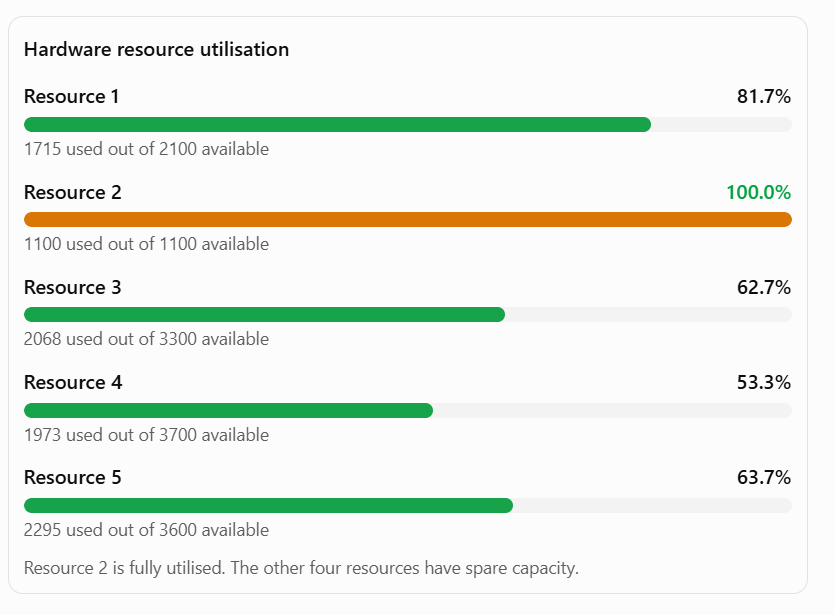

In [93]:
import pandas as pd

audit = pd.DataFrame({
    "Resource": [
        "Resource 1",
        "Resource 2",
        "Resource 3",
        "Resource 4",
        "Resource 5"
    ],
    "Used": [1715, 1100, 2068, 1973, 2295],
    "Capacity": [2100, 1100, 3300, 3700, 3600]
})

audit["Remaining"] = audit["Capacity"] - audit["Used"]

audit["Utilisation (%)"] = (
    audit["Used"] / audit["Capacity"]
) * 100

audit["Feasible"] = (
    audit["Used"] <= audit["Capacity"]
)

display(audit.round(2))

,Resource,Used,Capacity,Remaining,Utilisation (%),Feasible
0,Resource 1,1715,2100,385,81.67,True
1,Resource 2,1100,1100,0,100.00,True
2,Resource 3,2068,3300,1232,62.67,True
3,Resource 4,1973,3700,1727,53.32,True
4,Resource 5,2295,3600,1305,63.75,True


**1. Understand the CSV results**
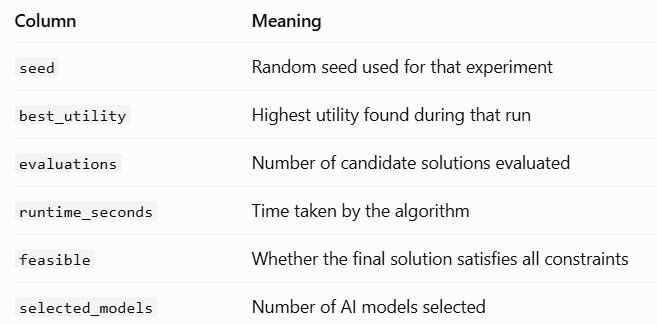

In [96]:
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files

uploaded = files.upload()

df = pd.read_csv("part1_hill_climber_results.csv")

display(df.head())

Saving part1_hill_climber_results.csv to part1_hill_climber_results (1).csv


,seed,best_utility,evaluations,runtime_seconds,feasible,selected_models
0,0,93712.0,3000,0.154634,True,15
1,1,129173.0,3000,0.109105,True,10
2,2,120735.0,3000,0.127763,True,12
3,3,82222.0,3000,0.115747,True,13
4,4,114469.0,3000,0.109574,True,10


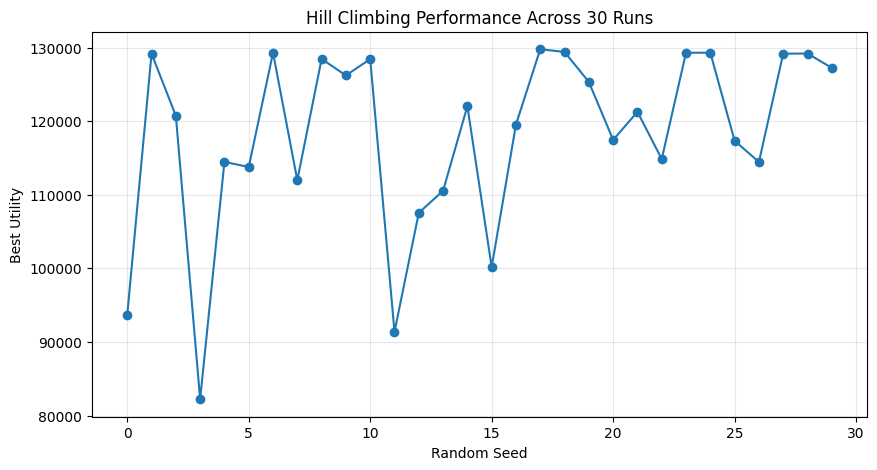

In [97]:
plt.figure(figsize=(10, 5))

plt.plot(
    df["seed"],
    df["best_utility"],
    marker="o"
)

plt.xlabel("Random Seed")
plt.ylabel("Best Utility")
plt.title("Hill Climbing Performance Across 30 Runs")

plt.grid(alpha=0.3)
plt.show()

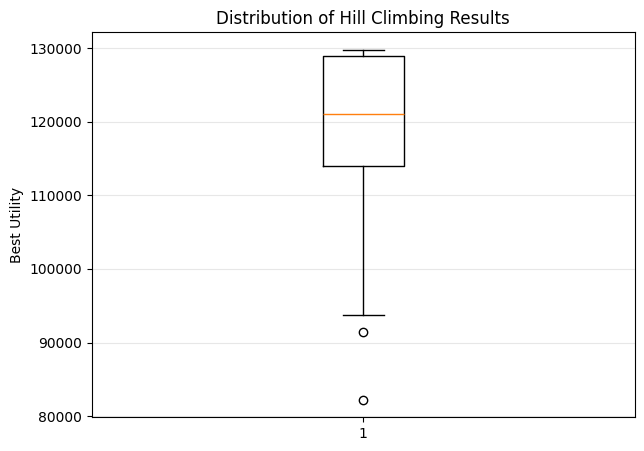

In [98]:
plt.figure(figsize=(7, 5))

plt.boxplot(df["best_utility"])

plt.ylabel("Best Utility")
plt.title("Distribution of Hill Climbing Results")

plt.grid(axis="y", alpha=0.3)
plt.show()

**### Boxplot Analysis of Hill Climbing Results**

The boxplot illustrates the distribution of the best utility values obtained from 30 independent Hill Climbing experiments. The median utility is approximately 121,000, indicating the central performance of the algorithm across the experimental runs.

The interquartile range shows that the middle 50% of the results are concentrated approximately between 114,000 and 129,000. This suggests that most experiments achieved relatively good solution quality.

However, two lower outliers are visible, with utility values of approximately 91,000 and 82,000. These results indicate that some experimental runs performed considerably worse than the majority. Such variation may be associated with different random initial solutions and search trajectories, which can lead the Hill Climbing algorithm towards different local optima.

Overall, the boxplot demonstrates that although Hill Climbing achieves relatively high utility in most experiments, its performance can vary depending on the random initialisation and search process. This provides motivation for investigating more advanced population-based optimisation methods.

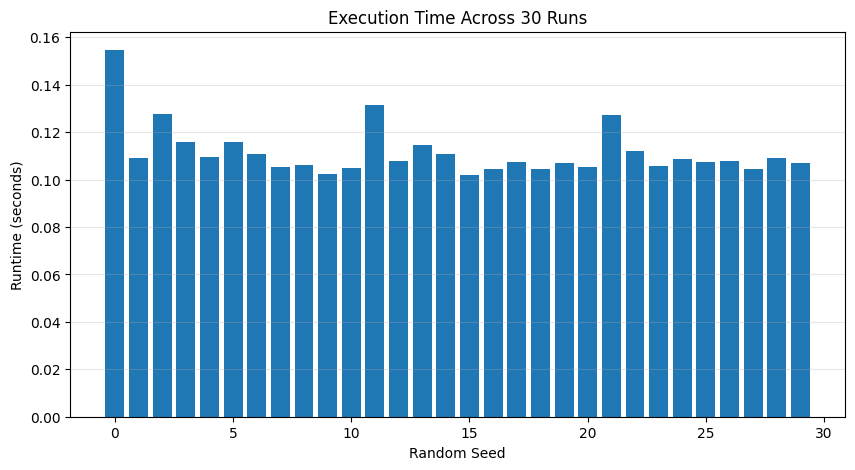

In [99]:
plt.figure(figsize=(10, 5))

plt.bar(
    df["seed"],
    df["runtime_seconds"]
)

plt.xlabel("Random Seed")
plt.ylabel("Runtime (seconds)")
plt.title("Execution Time Across 30 Runs")

plt.grid(axis="y", alpha=0.3)
plt.show()

**In Report **
### Execution Time Analysis

The execution time of the Hill Climbing algorithm was measured across 30 independent runs using different random seeds. The results show that the execution time varied approximately between 0.102 and 0.155 seconds, with an average runtime of approximately 0.112 seconds.

Most experiments completed within a relatively narrow time range of approximately 0.10–0.12 seconds. Some variations were observed between runs, potentially due to differences in the search paths, solution repair operations and system-level processing conditions.

Overall, the results indicate that the implemented Hill Climbing algorithm has relatively low computational overhead for the tested problem instance. The runtime results should be considered alongside solution utility and feasibility when evaluating the algorithm's overall performance.